# 02 — Thử nghiệm A: "Đây là ai trong danh sách?"
**Dự án:** Nhận diện khuôn mặt qua camera và chào hỏi theo tên

**Cách làm (giống hệt lúc camera chạy thật):**
```
Đăng ký : 10 người quen, mỗi người 5 ảnh  →  lưu vector
Test    : ảnh còn lại của người quen  +  300 người lạ
Với mỗi ảnh test: tìm người đăng ký gần nhất
    khoảng cách < ngưỡng  →  "Xin chào <tên>"
    khoảng cách >= ngưỡng →  coi là người lạ, không chào
```

**4 kết quả có thể xảy ra:**
| | Người quen | Người lạ |
|---|---|---|
| Máy chào | đúng tên ✔ / **gọi sai tên** ✘ | **chào nhầm người lạ** ✘ |
| Máy không chào | **bỏ sót** ✘ | đúng ✔ |

**Input:**
- `minhbodoi/face-vectors` (tạo ở notebook 01)
- LFW: `jessicali9530/lfw-dataset` (chỉ để xem ảnh ở Bước 7)

**Output:** Kaggle Dataset `minhbodoi/face-test-a`
```
face-test-a/
├── ket_qua.csv      ← mỗi model: ngưỡng chọn được và các tỉ lệ
└── loi_theo_nguong.png
```

> Không cần GPU.

## Bước 1: Cấu hình

In [1]:
import os

# ==== ĐƯỜNG DẪN ====
VEC_DIR    = '/kaggle/input/datasets/minhbodoi/face-vectors'
OUTPUT_DIR = '/kaggle/working/face-test-a'
os.makedirs(OUTPUT_DIR, exist_ok=True)

MODELS   = ['ArcFace', 'SFace', 'Facenet512', 'VGG-Face']
N_ENROLL = 5       # số ảnh đăng ký mỗi người quen
MAX_CHAO_NHAM = 0.01   # chấp nhận tối đa 1% người lạ bị chào nhầm

for f in ['images.csv'] + [f'{m}.npy' for m in MODELS]:
    print('OK   ' if os.path.exists(f'{VEC_DIR}/{f}') else 'SAI  ', f)

OK    images.csv
OK    ArcFace.npy
OK    SFace.npy
OK    Facenet512.npy
OK    VGG-Face.npy


## Bước 2: Đọc dữ liệu

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

images = pd.read_csv(f'{VEC_DIR}/images.csv')
vectors = {m: np.load(f'{VEC_DIR}/{m}.npy') for m in MODELS}

for m in MODELS:
    assert len(vectors[m]) == len(images), \
        f'{m}: {len(vectors[m])} vector nhưng images.csv có {len(images)} dòng. Chạy lại notebook 01 với CHAY_THU = False.'
print(f'images.csv: {len(images):,} dòng, khớp với số vector của cả {len(MODELS)} model')

# Chỉ dùng ảnh LFW tìm thấy mặt (camera thật cũng chỉ chào khi thấy mặt)
lfw = images[(images.source == 'lfw') & images.face_found]
print(f'Ảnh LFW dùng được: {len(lfw)}  (bỏ {((images.source == "lfw") & ~images.face_found).sum()} ảnh không thấy mặt)')

images.csv: 6,425 dòng, khớp với số vector của cả 4 model
Ảnh LFW dùng được: 441  (bỏ 0 ảnh không thấy mặt)


## Bước 3: Chia ảnh đăng ký / ảnh test
Mỗi người quen: 5 ảnh đầu để đăng ký, các ảnh còn lại để test.

In [3]:
known = lfw[lfw.group == 'known']
rank = known.groupby('person').cumcount()

enroll      = known[rank < N_ENROLL]
test_known  = known[rank >= N_ENROLL]
test_strange = lfw[lfw.group == 'stranger']

print(f'Đăng ký       : {enroll.person.nunique()} người, {len(enroll)} ảnh')
print(f'Test người quen: {len(test_known)} ảnh')
print(f'Test người lạ  : {len(test_strange)} ảnh')

Đăng ký       : 10 người, 50 ảnh
Test người quen: 91 ảnh
Test người lạ  : 300 ảnh


## Bước 4: Tìm người đăng ký gần nhất cho mỗi ảnh test
**Khoảng cách cosine:** 0 = giống hệt, càng lớn càng khác. Khoảng cách tới một người = khoảng cách tới ảnh đăng ký **gần nhất** của người đó.

In [4]:
def chuan_hoa(v):
    return v / np.linalg.norm(v, axis=1, keepdims=True)

def tim_gan_nhat(model, test_rows):
    V = chuan_hoa(vectors[model])
    dist = 1 - V[test_rows.index] @ V[enroll.index].T      # khoảng cách tới mọi ảnh đăng ký
    j = dist.argmin(axis=1)
    return enroll.person.values[j], dist.min(axis=1)

ket_qua = {}
for m in MODELS:
    ten_k, d_k = tim_gan_nhat(m, test_known)
    _,     d_s = tim_gan_nhat(m, test_strange)
    ket_qua[m] = {'dung_ten': ten_k == test_known.person.values, 'd_quen': d_k, 'd_la': d_s}
    print(f'{m:11s} khoảng cách TB  người quen: {d_k.mean():.3f}   người lạ: {d_s.mean():.3f}'
          f'   (người lạ gần nhất: {d_s.min():.3f})')

ArcFace     khoảng cách TB  người quen: 0.365   người lạ: 0.733   (người lạ gần nhất: 0.402)
SFace       khoảng cách TB  người quen: 0.414   người lạ: 0.702   (người lạ gần nhất: 0.463)
Facenet512  khoảng cách TB  người quen: 0.210   người lạ: 0.601   (người lạ gần nhất: 0.250)
VGG-Face    khoảng cách TB  người quen: 0.397   người lạ: 0.706   (người lạ gần nhất: 0.312)


## Bước 5: Thử nhiều ngưỡng, đếm lỗi
Ngưỡng **nhỏ** → khó tính: ít chào nhầm người lạ nhưng hay bỏ sót.
Ngưỡng **lớn** → dễ tính: ít bỏ sót nhưng hay chào nhầm.

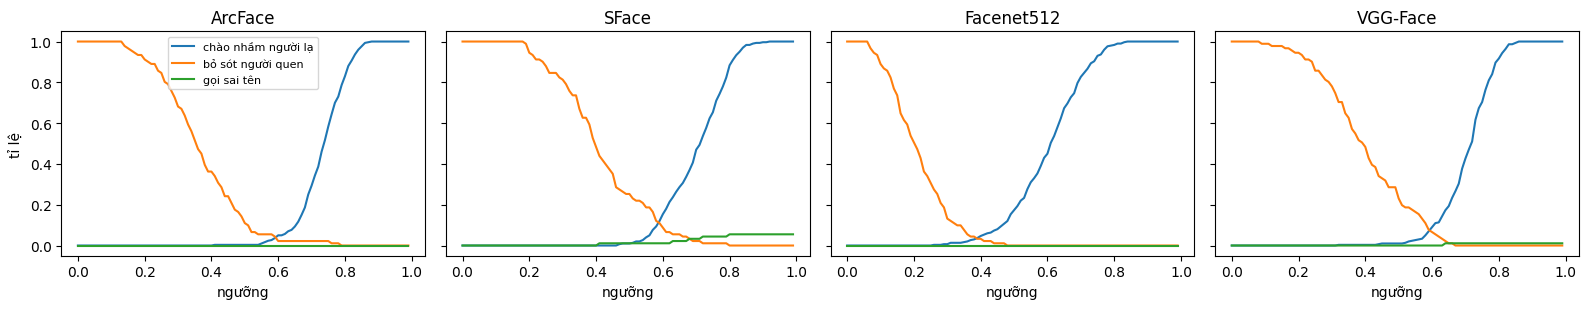

In [5]:
def dem_loi(r, nguong):
    chao_quen = r['d_quen'] < nguong
    return {
        'nguong'        : nguong,
        'dung_ten'      : (chao_quen & r['dung_ten']).mean(),
        'goi_sai_ten'   : (chao_quen & ~r['dung_ten']).mean(),
        'bo_sot'        : (~chao_quen).mean(),
        'chao_nham_la'  : (r['d_la'] < nguong).mean(),
    }

NGUONG = np.round(np.arange(0.0, 1.0, 0.01), 2)
bang = {m: pd.DataFrame([dem_loi(ket_qua[m], t) for t in NGUONG]) for m in MODELS}

fig, axes = plt.subplots(1, len(MODELS), figsize=(4 * len(MODELS), 3.2), sharey=True)
for ax, m in zip(axes, MODELS):
    b = bang[m]
    ax.plot(b.nguong, b.chao_nham_la, label='chào nhầm người lạ')
    ax.plot(b.nguong, b.bo_sot, label='bỏ sót người quen')
    ax.plot(b.nguong, b.goi_sai_ten, label='gọi sai tên')
    ax.set_title(m); ax.set_xlabel('ngưỡng')
axes[0].set_ylabel('tỉ lệ'); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/loi_theo_nguong.png', dpi=120); plt.show()

## Bước 6: Chọn ngưỡng cho từng model
Quy tắc: lấy ngưỡng **lớn nhất** mà người lạ bị chào nhầm **không quá 1%**. Rồi xem với ngưỡng đó, người quen được nhận đúng bao nhiêu.

In [6]:
rows = []
for m in MODELS:
    b = bang[m]
    chon = b[b.chao_nham_la <= MAX_CHAO_NHAM].iloc[-1]
    if chon.nguong == 0:
        print(f'CẢNH BÁO {m}: không có ngưỡng nào giữ chào nhầm <= 1%, vector của model này có thể bị hỏng')
    rows.append({'model': m, **chon.to_dict()})

tong_ket = pd.DataFrame(rows).set_index('model')
hien = tong_ket.copy()
for c in ['dung_ten', 'goi_sai_ten', 'bo_sot', 'chao_nham_la']:
    hien[c] = (hien[c] * 100).round(1).astype(str) + '%'
print(hien.to_string())

            nguong dung_ten goi_sai_ten bo_sot chao_nham_la
model                                                      
ArcFace       0.55    94.5%        0.0%   5.5%         1.0%
SFace         0.50    73.6%        1.1%  25.3%         1.0%
Facenet512    0.30    86.8%        0.0%  13.2%         0.7%
VGG-Face      0.51    80.2%        0.0%  19.8%         1.0%


## Bước 7: Xem các trường hợp chào nhầm
Hàng trên: người lạ. Hàng dưới: người quen mà model cho là giống nhất. `d` càng nhỏ, model càng chắc đó là cùng một người.

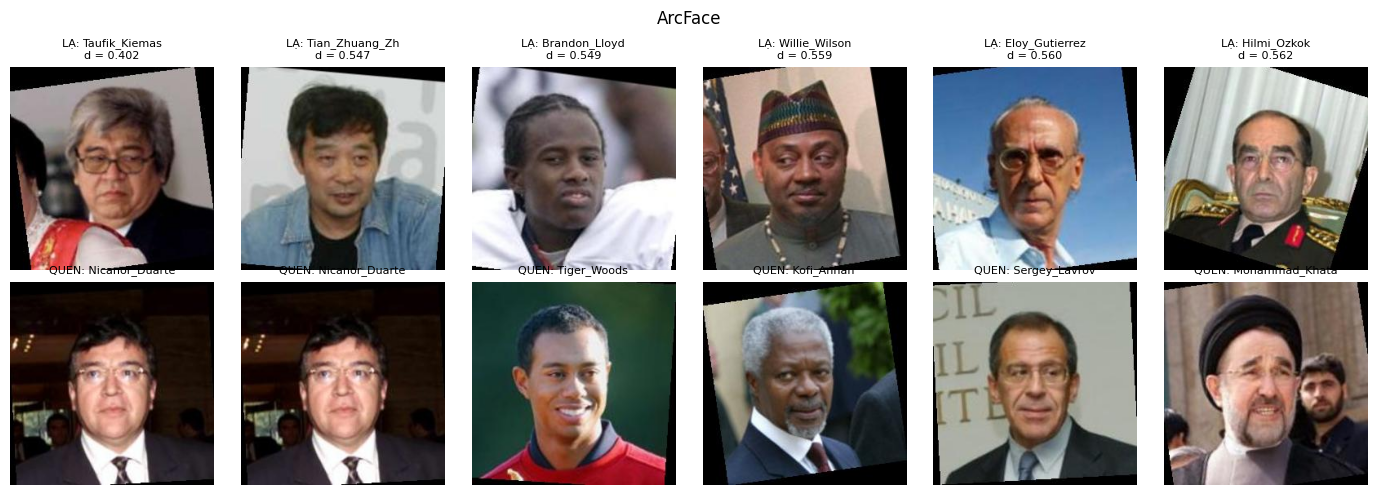

In [7]:
from PIL import Image

m = 'ArcFace'   # đổi tên model để xem model khác
V = chuan_hoa(vectors[m])
dist = 1 - V[test_strange.index] @ V[enroll.index].T
gan_nhat = dist.min(axis=1).argsort()[:6]

fig, axes = plt.subplots(2, 6, figsize=(14, 5))
for c, i in enumerate(gan_nhat):
    j = dist[i].argmin()
    la, quen = test_strange.iloc[i], enroll.iloc[j]
    axes[0, c].imshow(Image.open(la.path));   axes[0, c].set_title(f'LẠ: {la.person[:14]}\nd = {dist[i, j]:.3f}', fontsize=8)
    axes[1, c].imshow(Image.open(quen.path)); axes[1, c].set_title(f'QUEN: {quen.person[:14]}', fontsize=8)
for ax in axes.ravel():
    ax.axis('off')
fig.suptitle(m)
plt.tight_layout(); plt.savefig(f'{OUTPUT_DIR}/chao_nham_{m}.png', dpi=100); plt.show()

## Bước 8: Lưu và tạo Kaggle Dataset

In [8]:
tong_ket.to_csv(f'{OUTPUT_DIR}/ket_qua.csv')

# Tự động lưu kết quả thành Kaggle Dataset (Private)
import json, subprocess

dataset_name = os.path.basename(OUTPUT_DIR)
kaggle_user  = [l.split(':')[1].strip() for l in
                subprocess.run('kaggle config view', shell=True,
                               capture_output=True, text=True)
                .stdout.split('\n') if 'username' in l][0]

with open(f'{OUTPUT_DIR}/dataset-metadata.json', 'w') as f:
    json.dump({
        'title'   : dataset_name,
        'id'      : f'{kaggle_user}/{dataset_name}',
        'licenses': [{'name': 'CC0-1.0'}]
    }, f)

check = subprocess.run(f'kaggle datasets list --user {kaggle_user} --search {dataset_name}',
                       shell=True, capture_output=True, text=True)
if dataset_name in check.stdout:
    os.system(f'kaggle datasets version -p {OUTPUT_DIR} -m "update"')
else:
    os.system(f'kaggle datasets create -p {OUTPUT_DIR}')

print(f'Done! {kaggle_user}/{dataset_name}')

Starting upload for file ket_qua.csv


100%|██████████| 329/329 [00:00<00:00, 524B/s]


Upload successful: ket_qua.csv (329B)
Starting upload for file loi_theo_nguong.png


100%|██████████| 63.6k/63.6k [00:00<00:00, 103kB/s]
  0%|          | 0.00/634k [00:00<?, ?B/s]

Upload successful: loi_theo_nguong.png (64KB)
Starting upload for file chao_nham_ArcFace.png


100%|██████████| 634k/634k [00:00<00:00, 943kB/s]


Upload successful: chao_nham_ArcFace.png (634KB)
Dataset version is being created. Please check progress at https://www.kaggle.com/datasets/minhbodoi/face-test-a
Done! minhbodoi/face-test-a
